<a href="https://colab.research.google.com/github/leeknnn/viktoriiashkorubska-41/blob/master/lab_work_10/lab_work_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Вибірка денних температур:
 [25.06086341 19.47060897 19.67957062 18.31757844 23.16351907 15.24615326
 25.36202941 19.09698275 21.79759774 20.37657406 24.65526984 15.84964823
 20.19395699 20.03986411 23.83442361 18.25027183 20.56892948 18.80535396
 21.10553437 22.45703803 18.24845206 23.86180927 23.2539768  22.25623585
 23.25213987 19.29068035 20.69277444 18.66057641 20.3302798  22.32588867]
Середнє (mean): 20.850152723360946
Стандартне відхилення (std): 2.5227852196402956


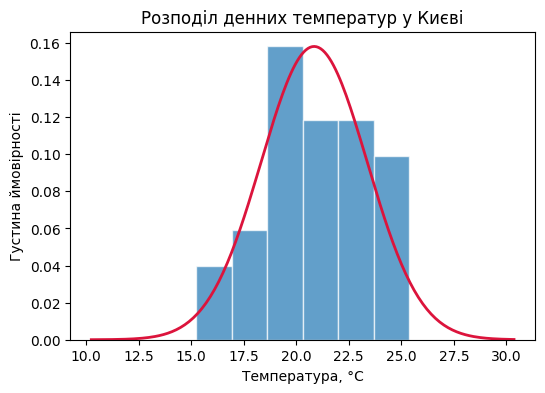

Ймовірність у межах [mean - std, mean + std]: 0.6827
95-й процентиль (температура): 25.00


In [7]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

np.random.seed(1)
daily_temps = np.random.normal(loc=21, scale=2.5, size=30)

print("Вибірка денних температур:\n", daily_temps)
print("Середнє (mean):", daily_temps.mean())
print("Стандартне відхилення (std):", daily_temps.std())

mean, std = daily_temps.mean(), daily_temps.std()
dist = stats.norm(loc=mean, scale=std)

plt.figure(figsize=(6, 4))
plt.hist(daily_temps, bins=6, density=True, edgecolor="white", alpha=0.7)
x = np.linspace(daily_temps.min() - 5, daily_temps.max() + 5, 200)
plt.plot(x, dist.pdf(x), color="crimson", linewidth=2)
plt.xlabel("Температура, °C")
plt.ylabel("Густина ймовірності")
plt.title("Розподіл денних температур у Києві")
plt.show()

p_interval = dist.cdf(mean + std) - dist.cdf(mean - std)
print(f"Ймовірність у межах [mean - std, mean + std]: {p_interval:.4f}")

p95 = dist.ppf(0.95)
print(f"95-й процентиль (температура): {p95:.2f}")

## Відповіді на контрольні питання

1. **У чому різниця між тим, що повертає .pdf(x), і тим, що повертає .cdf(x)?**
   - Функція `.pdf(x)` (функція густини ймовірності) повертає значення густини в конкретній точці $x$, яке вказує на відносну концентрацію ймовірності навколо цього значення. Функція `.cdf(x)` (функція розподілу) повертає сумарну накопичену ймовірність того, що випадкова величина набуде значення, меншого або рівного $x$ (тобто площу під кривою зліва від точки $x$).

2. **Чому значення .pdf(x) може бути більшим за 1, і чому це не суперечить теорії ймовірностей?**
   - Значення густини ймовірності (.pdf) вимірює не саму ймовірність конкретної події, а швидкість зміни накопиченої ймовірності (густину на одиницю довжини). Для неперервних випадкових величин густина в окремій точці може перевищувати одиницю, якщо розподіл дуже сконцентрований (мале значення $\sigma$), оскільки загальна інтегральна площа під всією кривою `.pdf(x)` у межах від мінус нескінченності до плюс нескінченності завжди суворо дорівнює 1.

3. **Чому .ppf() називають оберненою до .cdf() функцією?**
   - Вони виконують взаємно обернені операції. Функція `.cdf(x)` на вхід приймає значення випадкової величини, а на вихід дає накопичену ймовірність (частку даних нижче цього значення). Функція `.ppf(q)` (процентна точкова функція) на вхід приймає накопичену ймовірність $q$ (від 0 до 1), а на вихід дає порогове значення змінної, нижче якого лежить ця частка спостережень.